# RoomWise: Random Forest training

Run the cells from top to bottom. First upload **occupancy.csv** into Colab's Files pane.

This version uses short numbered cells and direct statements following the provided class activities. It keeps the original split, preprocessing, model settings, and evaluation. Random Forest and the PKL export are project-specific adaptations, not copied lesson algorithms.

**Sections:** (1) data inspection and preprocessing; (2) model and evaluation; (3) save the PKL; (4) optional interactive practice and lesson comparison; (5) website export information.

The main holdout passes the requirements. One chronological CV fold has a gap above 5 points. Keep that limitation in your defense.


## Step 1 — Import libraries
Short imports follow the activity style. Model-saving imports appear in the final export section.


In [1]:
# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.model_selection import cross_val_score, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import balanced_accuracy_score


## Step 2 — Import the dataset
Source: [UCI Occupancy Detection, Candanedo (2016)](https://archive.ics.uci.edu/dataset/357/occupancy+detection), CC BY 4.0, DOI 10.24432/C5X01N. Three original files are combined and ordered by time. The CSV preserves all original variables; the model will use four only.


In [2]:
# Step 2: Import dataset
# Upload occupancy.csv to Colab before running this cell.
occupancydf = pd.read_csv('occupancy.csv')
print(occupancydf)


                      date  Temperature  ...  HumidityRatio  Occupancy
0      2015-02-02 14:19:00      23.7000  ...       0.004764          1
1      2015-02-02 14:19:59      23.7180  ...       0.004773          1
2      2015-02-02 14:21:00      23.7300  ...       0.004765          1
3      2015-02-02 14:22:00      23.7225  ...       0.004744          1
4      2015-02-02 14:23:00      23.7540  ...       0.004767          1
...                    ...          ...  ...            ...        ...
20555  2015-02-10 09:29:00      21.0500  ...       0.005579          1
20556  2015-02-10 09:29:59      21.0500  ...       0.005563          1
20557  2015-02-10 09:30:59      21.1000  ...       0.005596          1
20558  2015-02-10 09:32:00      21.1000  ...       0.005621          1
20559  2015-02-10 09:33:00      21.1000  ...       0.005612          1

[20560 rows x 7 columns]


## Step 3 — Check missing values
The real dataset has complete measurements. We still check rather than assume.


In [3]:
# Step 3: Perform data preprocessing — check null values
print(occupancydf.isnull().sum())


date             0
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64


## Step 4 — Get to know the data: information


In [4]:
# Step 4: Get to know the data
occupancydf.info()


<class 'pandas.DataFrame'>
RangeIndex: 20560 entries, 0 to 20559
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           20560 non-null  str    
 1   Temperature    20560 non-null  float64
 2   Humidity       20560 non-null  float64
 3   Light          20560 non-null  float64
 4   CO2            20560 non-null  float64
 5   HumidityRatio  20560 non-null  float64
 6   Occupancy      20560 non-null  int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 1.1 MB


## Step 5 — Get to know the data: descriptive statistics


In [5]:
# Step 5: Get to know the data
print(occupancydf.describe())


        Temperature      Humidity  ...  HumidityRatio     Occupancy
count  20560.000000  20560.000000  ...   20560.000000  20560.000000
mean      20.906212     27.655925  ...       0.004228      0.231031
std        1.055315      4.982154  ...       0.000768      0.421503
min       19.000000     16.745000  ...       0.002674      0.000000
25%       20.200000     24.500000  ...       0.003719      0.000000
50%       20.700000     27.290000  ...       0.004292      0.000000
75%       21.525000     31.290000  ...       0.004832      0.000000
max       24.408333     39.500000  ...       0.006476      1.000000

[8 rows x 6 columns]


## Step 6 — Check shape and duplicate rows
Rows are minute-level observations from one source room, not 20,560 independent buildings.


In [6]:
# Step 6: Shape and duplicate check
print('Original shape:', occupancydf.shape)
print('Exact duplicate rows:', occupancydf.duplicated().sum())
occupancydf = occupancydf.drop_duplicates().copy()
occupancydf['date'] = pd.to_datetime(occupancydf['date'])
occupancydf = occupancydf.sort_values('date').reset_index(drop=True)
print('Cleaned shape:', occupancydf.shape)
print('Repeated timestamps:', occupancydf['date'].duplicated().sum())
print('Target counts:')
print(occupancydf['Occupancy'].value_counts().sort_index())


Original shape: (20560, 7)
Exact duplicate rows: 0
Cleaned shape: (20560, 7)
Repeated timestamps: 0
Target counts:
Occupancy
0    15810
1     4750
Name: count, dtype: int64


## Step 7 — Select relevant columns
Keep `date` separately for chronological splitting. Exclude row IDs and `HumidityRatio` from prediction. Humidity ratio is derived from temperature and humidity; the four-input design was specified before this run. Valid unusual readings are retained. No synthetic rows or artificial labels are added.


In [7]:
# Step 7: Drop unnecessary columns for the prediction task
dates = occupancydf['date'].copy()
occupancydf = occupancydf.drop('date', axis=1)
occupancydf = occupancydf.drop('HumidityRatio', axis=1)
print(occupancydf)
print(occupancydf.isnull().sum())


       Temperature  Humidity       Light          CO2  Occupancy
0          23.7000   26.2720  585.200000   749.200000          1
1          23.7180   26.2900  578.400000   760.400000          1
2          23.7300   26.2300  572.666667   769.666667          1
3          23.7225   26.1250  493.750000   774.750000          1
4          23.7540   26.2000  488.600000   779.000000          1
...            ...       ...         ...          ...        ...
20555      20.8150   27.7175  429.750000  1505.250000          1
20556      20.8650   27.7450  423.500000  1514.500000          1
20557      20.8900   27.7450  423.500000  1521.500000          1
20558      20.8900   28.0225  418.750000  1632.000000          1
20559      21.0000   28.1000  409.000000  1864.000000          1

[20560 rows x 5 columns]
Temperature    0
Humidity       0
Light          0
CO2            0
Occupancy      0
dtype: int64


## Step 8 - Features and target
Use `.drop()` and column selection, as in AI1 page 28. `X` stays a dataframe, so we do not convert it into an array and then back into a dataframe.

In [8]:
# Step 8: Identify features and target
X = occupancydf.drop('Occupancy', axis=1)
y = occupancydf['Occupancy']
feature_names = X.columns.tolist()
print(X)
print(y)


       Temperature  Humidity       Light          CO2
0          23.7000   26.2720  585.200000   749.200000
1          23.7180   26.2900  578.400000   760.400000
2          23.7300   26.2300  572.666667   769.666667
3          23.7225   26.1250  493.750000   774.750000
4          23.7540   26.2000  488.600000   779.000000
...            ...       ...         ...          ...
20555      20.8150   27.7175  429.750000  1505.250000
20556      20.8650   27.7450  423.500000  1514.500000
20557      20.8900   27.7450  423.500000  1521.500000
20558      20.8900   28.0225  418.750000  1632.000000
20559      21.0000   28.1000  409.000000  1864.000000

[20560 rows x 4 columns]
0        1
1        1
2        1
3        1
4        1
        ..
20555    1
20556    1
20557    1
20558    1
20559    1
Name: Occupancy, Length: 20560, dtype: int64


## Step 9 — Encoding decision
All four predictors are continuous numeric measurements and the target is already binary. Therefore **no OneHotEncoder, OrdinalEncoder, or LabelEncoder is applied**. The encoding stage is considered and documented, not silently omitted. See Data Preprocessing Part 2 p. 17 and AI2 p. 37.


In [9]:
# Step 9: Check if encoding is needed
print(X.dtypes)
print(y.unique())
print('All inputs are numeric. Occupancy is already 0 or 1.')
print('No label encoder is needed.')


Temperature    float64
Humidity       float64
Light          float64
CO2            float64
dtype: object
[1 0]
All inputs are numeric. Occupancy is already 0 or 1.
No label encoder is needed.


## Step 10 - Separate training, validation, and test data
Keep the chronological split unchanged. These are minute-level observations: the lessons warn against shuffling time-series data (AI1 pages 18 and 21; Data Preprocessing Part 2 page 31). The two 60-reading buffers are project-specific additions. The final split is 12,336 training, 4,052 validation, 4,052 test, and 120 buffer records.

In [10]:
# Step 10: Split the data in time order
# First reserve the final 20% for testing.
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.20, shuffle=False)

# Use 25% of the earlier 80% for validation (20% of the full dataset).
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development, test_size=0.25, shuffle=False)

# Leave 60 readings between training/validation and validation/test.
X_validation = X_validation.iloc[60:]
y_validation = y_validation.iloc[60:]
X_test = X_test.iloc[60:]
y_test = y_test.iloc[60:]

print('Training:', X_train.shape)
print('Validation:', X_validation.shape)
print('Testing:', X_test.shape)
print('Excluded buffer records:', 120)


Training: (12336, 4)
Validation: (4052, 4)
Testing: (4052, 4)
Excluded buffer records: 120


## Step 11 — Visualize training data
The pipeline activity uses box plots. Use the training subset for detailed exploration so evaluation periods do not drive preprocessing choices. Outliers are inspected, not automatically deleted.


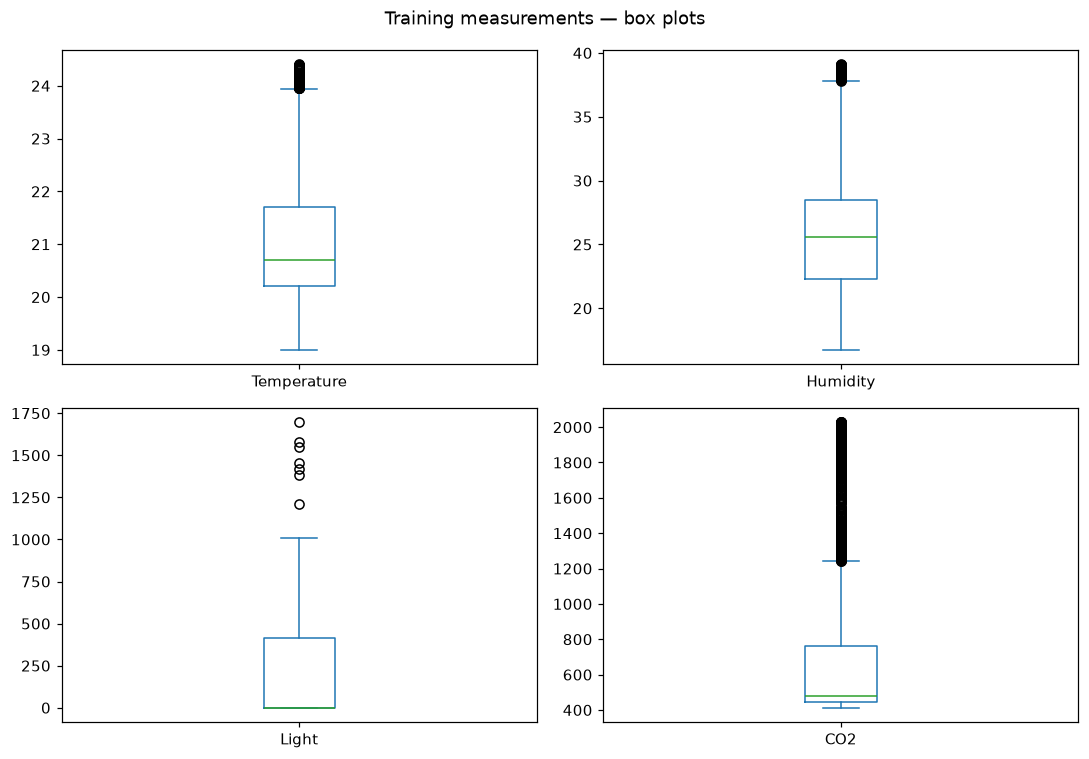

In [11]:
# Step 11: Visualization
X_train.plot(kind='box', subplots=True, layout=(2, 2), sharex=False, sharey=False,
             figsize=(10, 7))
plt.suptitle('Training measurements — box plots')
plt.tight_layout()
plt.show()


## Step 12 — Check correlations
This corresponds to AI2 pp. 37–38. Correlation describes the training data; it does not establish causation. Correlated predictors need not be removed from a Random Forest automatically.


             Temperature  Humidity     Light       CO2
Temperature     1.000000 -0.049097  0.655458  0.597588
Humidity       -0.049097  1.000000  0.097879  0.444851
Light           0.655458  0.097879  1.000000  0.685222
CO2             0.597588  0.444851  0.685222  1.000000


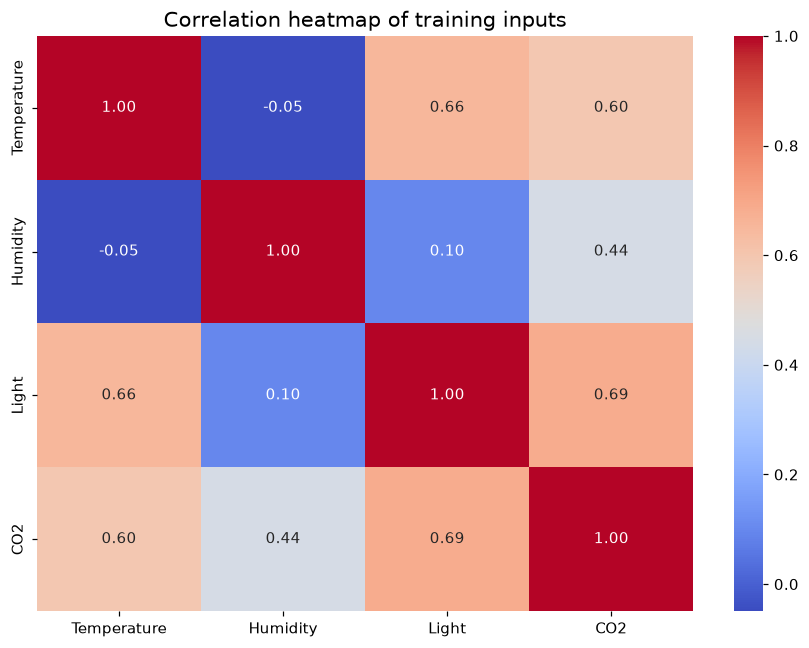

In [12]:
# Step 12: Correlation matrix and heatmap
correlation_matrix = X_train.corr()
print(correlation_matrix)
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation heatmap of training inputs', fontsize=14)
plt.tight_layout()
plt.show()


## Step 13 — Multicollinearity diagnostic
AI2 pp. 39–40 uses statsmodels VIF with an intercept. We use those same library calls here. VIF is relevant to coefficient interpretation in regression, not a requirement of Random Forest. It is retained as a learning diagnostic; no automatic feature removal is performed. Only training measurements are used.


In [13]:
# Step 13: Check correlation using VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
X_const = add_constant(X_train)
vif_data = pd.DataFrame()
vif_data['Feature'] = X_const.columns
vif_data['VIF'] = [variance_inflation_factor(X_const.values, i)
                   for i in range(X_const.shape[1])]
print(vif_data)
print('The constant is the intercept. Interpret the predictor VIFs separately.')
print('VIF is descriptive here; Random Forest has no regression coefficients.')


       Feature       VIF
0        const  1.000000
1  Temperature  2.162825
2     Humidity  1.585530
3        Light  2.353928
4          CO2  3.120344
The constant is the intercept. Interpret the predictor VIFs separately.
VIF is descriptive here; Random Forest has no regression coefficients.


## Step 14 — Build the preprocessing and model pipeline
Follow the Pipeline lesson p. 21: median imputation, StandardScaler, then classifier. Replace LogisticRegression with RandomForestClassifier. Random Forest does not require scaling; **it is retained to demonstrate the class pipeline**. Imputer/scaler are fitted on training data inside the pipeline and re-fitted within each cross-validation fold. No data leakage from fitting them to the full dataset. Settings were selected in the earlier feasibility experiment, not by this run’s test results.


In [14]:
# Step 14: Build the pipeline
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=2
)

pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', model)
])
print(pipeline)


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 RandomForestClassifier(max_depth=10, min_samples_leaf=5,
                                        n_estimators=200, n_jobs=2,
                                        random_state=42))])


## Step 15 — Fit the pipeline to training data


In [15]:
# Step 15: Fit the pipeline
pipeline.fit(X_train, y_train)
print('Pipeline fitted on training data only.')


Pipeline fitted on training data only.


## Step 16 — Verify preprocessing
This mirrors the imputer inspection in the Pipeline lesson p. 22.


In [16]:
# Step 16: Check null values after pipeline implementation
imputer = pipeline.named_steps['imputer']
X_train_imputed = imputer.transform(X_train)
print(pd.DataFrame(X_train_imputed, columns=feature_names).isnull().sum())
print('Scaled training preview:')
print(pipeline.named_steps['scaler'].transform(X_train_imputed)[:5])


Temperature    0
Humidity       0
Light          0
CO2            0
dtype: int64
Scaled training preview:
[[2.435658   0.1222502  2.08728242 0.37502064]
 [2.45144693 0.12604008 2.05538588 0.41253007]
 [2.46197289 0.11340715 2.02849272 0.44356466]
 [2.45539416 0.09129953 1.65832086 0.46058903]
 [2.48302479 0.10709069 1.63416392 0.47482252]]


## Step 17 — Predict validation data
AI1 pp. 30–31 demonstrates `.predict` and one-sample input. The independent test period stays reserved.


In [17]:
# Step 17: Predict validation data
y_validation_pred = pipeline.predict(X_validation)
print(y_validation_pred)
print(pd.DataFrame({'Actual': y_validation, 'Predicted': y_validation_pred}).head(15))


[1 1 1 ... 0 0 0]
       Actual  Predicted
12396       1          1
12397       1          1
12398       1          1
12399       1          1
12400       1          1
12401       1          1
12402       1          1
12403       1          1
12404       1          1
12405       1          1
12406       1          1
12407       1          1
12408       1          1
12409       1          1
12410       1          1


## Step 18 - Try one prediction
Change the four simple variables below, then run the cell. The optional input() exercise appears after the main training steps so Run all does not wait for typed answers.

In [18]:
# Step 18: Predict one new reading
# Change these four numbers to try another input.
temperature = 23.0
humidity = 35.0
light = 400.0
co2 = 900.0

user_input = pd.DataFrame(
    [[temperature, humidity, light, co2]],
    columns=feature_names
)
prediction = pipeline.predict(user_input)
print(user_input)

if prediction[0] == 1:
    print('Occupied')
else:
    print('Unoccupied')


   Temperature  Humidity  Light    CO2
0         23.0      35.0  400.0  900.0
Occupied


## Step 19 — Five-fold cross-validation
Follow AI1 pp. 32–33 using `cross_val_score`, replacing ordinary folds with `TimeSeriesSplit(n_splits=5, gap=60)` according to that same lesson’s time-series guidance. Each fold trains on earlier observations and validates on later ones. The validation/test holdouts are excluded.


In [19]:
# Step 19: Cross-validation
time_cv = TimeSeriesSplit(n_splits=5, gap=60)
cv_scores = cross_val_score(pipeline, X_train, y_train,
                            cv=time_cv, scoring='accuracy')
print('Cross-validation accuracy per fold:')
print(cv_scores)
print('Average cross-validation accuracy:', cv_scores.mean())


Cross-validation accuracy per fold:
[0.96060311 0.99124514 0.91828794 0.99708171 0.9868677 ]
Average cross-validation accuracy: 0.9708171206225682


## Step 20 — Training and validation accuracy
Report percentages without hiding failures. The updated rule is interpreted as validation accuracy **at least 85%** and absolute gap **strictly less than 5 percentage points**.


In [20]:
# Step 20: Check training and validation accuracy
train_accuracy = pipeline.score(X_train, y_train)
validation_accuracy = pipeline.score(X_validation, y_validation)
gap = abs(train_accuracy - validation_accuracy) * 100

print('Training accuracy (%):', round(train_accuracy * 100, 2))
print('Validation accuracy (%):', round(validation_accuracy * 100, 2))
print('Gap (percentage points):', round(gap, 2))

valid = validation_accuracy >= 0.85 and gap < 5
if valid:
    print('Main holdout verdict: VALID')
else:
    print('Main holdout verdict: INVALID')


Training accuracy (%): 99.28
Validation accuracy (%): 99.09
Gap (percentage points): 0.19
Main holdout verdict: VALID


## Step 21 — Verify the gap in each chronological fold
`cross_validate` is listed in AI1 p. 24. This additional diagnostic reports matching training and validation scores for every fold, rather than comparing unrelated training and CV scores.


In [21]:
# Step 21: Check the training-validation gap in each fold
cv_results = cross_validate(
    pipeline, X_train, y_train,
    cv=time_cv,
    scoring='accuracy',
    return_train_score=True
)

cv_table = pd.DataFrame()
cv_table['Fold'] = [1, 2, 3, 4, 5]
cv_table['Training (%)'] = cv_results['train_score'] * 100
cv_table['Validation (%)'] = cv_results['test_score'] * 100
cv_table['Gap (points)'] = abs(
    cv_table['Training (%)'] - cv_table['Validation (%)'])
cv_table['Valid'] = (cv_table['Validation (%)'] >= 85) & (cv_table['Gap (points)'] < 5)
print(cv_table)


   Fold  Training (%)  Validation (%)  Gap (points)  Valid
0     1     98.997996       96.060311      2.937685   True
1     2     99.136229       99.124514      0.011715   True
2     3     99.181401       91.828794      7.352608  False
3     4     99.363057       99.708171      0.345114   True
4     5     99.452055       98.686770      0.765284   True


## Step 22 — Confusion matrix and classification report
Matches AI1 pp. 33–34 and AI2 p. 43. Rows are actual labels; columns are predictions. Explicit labels prevent reversed descriptions.


In [22]:
# Step 22: Print confusion matrix and classification report
cm = confusion_matrix(y_validation, y_validation_pred, labels=[0, 1])
confusion = pd.DataFrame(cm, index=['Actual unoccupied', 'Actual occupied'],
                          columns=['Predicted unoccupied', 'Predicted occupied'])
print(confusion)
print(classification_report(y_validation, y_validation_pred, labels=[0, 1],
                            target_names=['Unoccupied', 'Occupied'], zero_division=0))


                   Predicted unoccupied  Predicted occupied
Actual unoccupied                  3495                  34
Actual occupied                       3                 520
              precision    recall  f1-score   support

  Unoccupied       1.00      0.99      0.99      3529
    Occupied       0.94      0.99      0.97       523

    accuracy                           0.99      4052
   macro avg       0.97      0.99      0.98      4052
weighted avg       0.99      0.99      0.99      4052



## Step 23 — Final evaluation on the reserved test period
Evaluate the same trained pipeline; do not refit on validation/test records or tune against these results. This split has already been investigated during feasibility work, so local-school data are still needed for a truly external confirmation.


In [23]:
# Step 23: Predict and evaluate test data
y_pred = pipeline.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print(f'Test accuracy: {test_accuracy * 100:.2f}%')
print(f'Balanced test accuracy: {balanced_accuracy_score(y_test, y_pred) * 100:.2f}%')
print(f'Majority-class baseline: {pd.Series(y_test).value_counts(normalize=True).max() * 100:.2f}%')
test_cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print(pd.DataFrame(test_cm, index=['Actual unoccupied', 'Actual occupied'],
                   columns=['Predicted unoccupied', 'Predicted occupied']))
print(classification_report(y_test, y_pred, labels=[0, 1],
                            target_names=['Unoccupied', 'Occupied'], zero_division=0))


Test accuracy: 99.53%
Balanced test accuracy: 99.59%
Majority-class baseline: 72.93%
                   Predicted unoccupied  Predicted occupied
Actual unoccupied                  2939                  16
Actual occupied                       3                1094
              precision    recall  f1-score   support

  Unoccupied       1.00      0.99      1.00      2955
    Occupied       0.99      1.00      0.99      1097

    accuracy                           1.00      4052
   macro avg       0.99      1.00      0.99      4052
weighted avg       1.00      1.00      1.00      4052



## Step 24 — Interpret the results
AI1 p. 35 asks for interpretation. The next cell generates statements directly from measured values. High performance in this room does not establish accuracy in a different building. Adjacent readings are related even with chronological buffers.


In [24]:
# Step 24: Interpretation
print(f'The model correctly classified {test_cm.trace()} of {len(y_test)} test observations.')
print(f'Occupied observations missed: {test_cm[1, 0]}.')
print(f'Empty observations flagged occupied: {test_cm[0, 1]}.')
print(f'The training-validation gap is {gap:.2f} percentage points.')
print('Holdout criteria met:', valid)
print('All five chronological folds meet both criteria:', bool(cv_table['Valid'].all()))
print('The model predicts current occupancy, not future attendance or electricity savings.')


The model correctly classified 4033 of 4052 test observations.
Occupied observations missed: 3.
Empty observations flagged occupied: 16.
The training-validation gap is 0.19 percentage points.
Holdout criteria met: True
All five chronological folds meet both criteria: False
The model predicts current occupancy, not future attendance or electricity savings.


## Step 25 - Save the model for Flask
Use Python's `pickle.dump` to save the **whole pipeline**. This is a website deployment addition. Flask will load this file once with `pickle.load` and call `.predict()` and `.predict_proba()` on raw readings. This prevents omitted or repeated scaling.

In [25]:
# Step 25: Save the complete trained pipeline as a PKL file
import pickle
from pathlib import Path

artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)

with open('artifacts/roomwise_pipeline.pkl', 'wb') as file:
    pickle.dump(pipeline, file)

print('Saved: artifacts/roomwise_pipeline.pkl')
print('This file contains the imputer, scaler, and Random Forest.')


Saved: artifacts/roomwise_pipeline.pkl
This file contains the imputer, scaler, and Random Forest.


## After running in Google Colab
Download roomwise_pipeline.pkl, metadata.json, and test_predictions.csv from the artifacts folder after all cells finish. Put these files into RoomWise_Notebook/artifacts and run Prepare_Model_For_Website.py to copy the needed files and three demonstration examples into the sibling RoomWise system. Restart Flask afterward. Match the scikit-learn version recorded in metadata before loading the PKL.

### What remains unproven
No actual electricity savings or school-room accuracy have been measured. The source records come from one office. Staff review remains necessary.

## Follow-up robustness check

After the five-fold result exposed a gap failure, five simpler configurations were checked on the same training-only chronological folds. None made every fold meet the gap threshold. These checks did not use validation or test results for selection, and the exported model remains unchanged. See `artifacts/training_only_tuning.json` in the delivery package. The main holdout passes, while this stricter check remains a limitation.


## Appendix — Compare with a simpler model

AI1 pp. 36–50 demonstrates comparing models. This appendix compares the existing forest with the logistic-regression pipeline taught in AI2, using the same training-only chronological folds. It does not alter the exported model or use the final test labels for model selection. Random Forest is the assignment requirement; it need not win every comparison.


In [26]:
# Compare two models using the same training folds
from sklearn.linear_model import LogisticRegression
logisticPipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])
logistic_scores = cross_val_score(logisticPipeline, X_train, y_train,
                                cv=time_cv, scoring='accuracy')
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Logistic Regression'],
    'Mean chronological CV accuracy (%)': [cv_scores.mean() * 100,
                                            logistic_scores.mean() * 100]
})
print(comparison.to_string(index=False))
print('Logistic regression fold scores:', logistic_scores)
print('This comparison does not establish performance in a different room.')


              Model  Mean chronological CV accuracy (%)
      Random Forest                           97.081712
Logistic Regression                           97.500000
Logistic regression fold scores: [0.95963035 0.94309339 0.99805447 0.98638132 0.98784047]
This comparison does not establish performance in a different room.


The assignment requires Random Forest, so it remains the deployed model. If the simpler model performs similarly or better here, state that honestly: the result supports considering a simpler baseline in future work. This is not proof that Random Forest is universally best.


## Optional practice - typed input
The class uses input() to enter measurements. Set RUN_INTERACTIVE to True only when you want to type values. This does not train or change the model.

In [27]:
RUN_INTERACTIVE = False
if RUN_INTERACTIVE:
    temperature = float(input('Temperature (C): '))
    humidity = float(input('Humidity (%): '))
    light = float(input('Light (lux): '))
    co2 = float(input('CO2 (ppm): '))
    user_input = pd.DataFrame([[temperature, humidity, light, co2]], columns=feature_names)
    print('Predicted occupancy (0 = empty, 1 = occupied):', pipeline.predict(user_input)[0])
else:
    print('Typed-input practice skipped. Use Step 18 for a Run-all example.')


Typed-input practice skipped. Use Step 18 for a Run-all example.


## Website export - keep the recorded examples
These lines save evaluation records, not extra training. They are separate from the main lesson steps. The website uses three records from the test period to demonstrate a correct empty result, a correct occupied result, and a real mistake.

In [28]:
demo = X_test.copy()
demo['Actual'] = y_test
demo['Predicted'] = y_pred
demo['Timestamp'] = dates.loc[X_test.index].astype(str)
demo.to_csv('artifacts/test_predictions.csv', index=False)
X_test.to_csv('artifacts/demo_inputs.csv', index=False)
print('Saved recorded test examples.')


Saved recorded test examples.


## Website export - save evaluation information
A dictionary stores named values. JSON lets Flask read the metrics and training ranges. These values are calculated above, not typed-in accuracy claims. This is deployment code, not part of model fitting.

In [29]:
import json
import sklearn

metadata = {}
metadata['features'] = feature_names
metadata['training_accuracy'] = float(train_accuracy)
metadata['validation_accuracy'] = float(validation_accuracy)
metadata['gap_points'] = float(gap)
metadata['test_accuracy'] = float(test_accuracy)
metadata['test_confusion_matrix'] = test_cm.tolist()
metadata['cv'] = cv_table.to_dict(orient='records')
metadata['criteria_met'] = bool(valid)
metadata['all_cv_folds_valid'] = bool(cv_table['Valid'].all())
metadata['records'] = {
    'total': len(occupancydf),
    'training': len(X_train),
    'validation': len(X_validation),
    'test': len(X_test),
    'buffer': 120
}
metadata['training_ranges'] = {}
for name in feature_names:
    metadata['training_ranges'][name] = {
        'min': float(X_train[name].min()),
        'max': float(X_train[name].max())
    }
metadata['versions'] = {
    'sklearn': sklearn.__version__,
    'pandas': pd.__version__,
    'numpy': np.__version__
}
metadata['source'] = 'https://archive.ics.uci.edu/dataset/357/occupancy+detection'

with open('artifacts/metadata.json', 'w') as file:
    json.dump(metadata, file, indent=2)

print('Saved: artifacts/metadata.json')


Saved: artifacts/metadata.json


## Use the trained model in the system
Keep RoomWise_Notebook beside RoomWise. Run Prepare_Model_For_Website.py from RoomWise_Notebook, then run app.py from RoomWise and open http://127.0.0.1:5080/. The helper copies the PKL and evaluation information; it does not train another model. The notebook does not need to stay open. Only load a PKL you created or trust.